<a href="https://colab.research.google.com/github/salwa-ayudia/pm-turi4-clustering/blob/main/TuRi4_Salwa_Ayudia_Putri_2488010042.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah Praktikum

In [89]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
data = {
    'usia': [19, 22, 18, 45, 17, 42, 20, 27, 18, 30],
    'pendapatan': [5_000_000, 8_300_000, 7_500_000, 20_000_000, 5_700_000, 19_000_000, 9_100_000, 3_300_000, 10_000_000, 10_900_000],
    'skor_belanja': [20, 30, 40, 45, 50, 55, 60, 65, 70, 90],
}
df = pd.DataFrame(data)
print(display(df))
X_scaled = StandardScaler().fit_transform(df)

,usia,pendapatan,skor_belanja
0,19,5000000,20
1,22,8300000,30
2,18,7500000,40
3,45,20000000,45
4,17,5700000,50
5,42,19000000,55
6,20,9100000,60
7,27,3300000,65
8,18,10000000,70
9,30,10900000,90


None


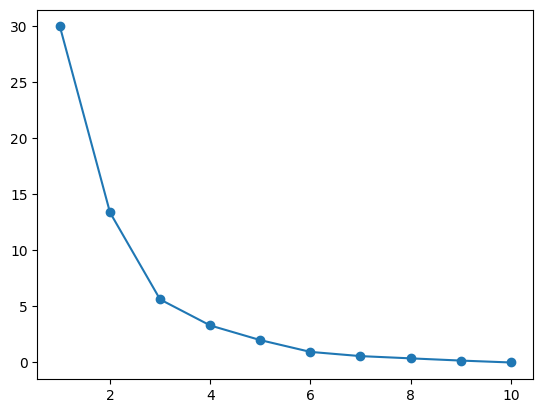

In [90]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

## K-Means with K=3

In [91]:
kmeans_k3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_k3 = df.copy()
df_k3['cluster'] = kmeans_k3.fit_predict(X_scaled)
print(df_k3['cluster'].value_counts())

cluster
2    4
1    4
0    2
Name: count, dtype: int64


In [92]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df_k3['cluster']))

0.4622975331303184


In [93]:
profil = df_k3.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

         usia  pendapatan  skor_belanja
cluster                                
0        43.5  19500000.0          50.0
1        23.8   8325000.0          71.2
2        19.0   6625000.0          35.0


## K-Means with K=5

In [94]:
kmeans_k5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df_k5 = df.copy()
df_k5['cluster'] = kmeans_k5.fit_predict(X_scaled)
print(df_k5['cluster'].value_counts())

cluster
0    3
2    3
1    2
4    1
3    1
Name: count, dtype: int64


In [95]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df_k5['cluster']))

0.3726996323290993


In [96]:
profil = df_k5.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        19.7   6933333.3          30.0
1        43.5  19500000.0          50.0
2        18.3   8266666.7          60.0
3        30.0  10900000.0          90.0
4        27.0   3300000.0          65.0


## K-Means K=3 tanpa Scaling

In [97]:
kmeans_k3_noScaling = KMeans(n_clusters=3, random_state=42, n_init=10)
df_k3_noScaling = df.copy()
df_k3_noScaling['cluster'] = kmeans_k3_noScaling.fit_predict(df)
print(df_k3_noScaling['cluster'].value_counts())

cluster
1    5
2    3
0    2
Name: count, dtype: int64


In [98]:
from sklearn.metrics import silhouette_score
print(silhouette_score(df, df_k3_noScaling['cluster']))

0.6663764581830496


In [99]:
profil = df_k3_noScaling.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        43.5  19500000.0          50.0
1        21.6   9160000.0          58.0
2        21.0   4666666.7          45.0


## Latihan Mandiri

### 6. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.


Silhouette score k=3 adalah 0.4622975331303184,<br>
Silhouette score k=5 adalah 0.3726996323290993

### 7. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

Hasilnya **0.6663764581830496**, Kesimpulan yang di dapat adalah dengan tanpa scaling, hasil silhouette score nya justru mendekati 1 yang artinya pengelompokan **cenderung baik** karena Data berada dekat dengan anggota clusternya sendiri dan jauh dari cluster lain.

### 8. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

#### Scatter plot untuk K=3

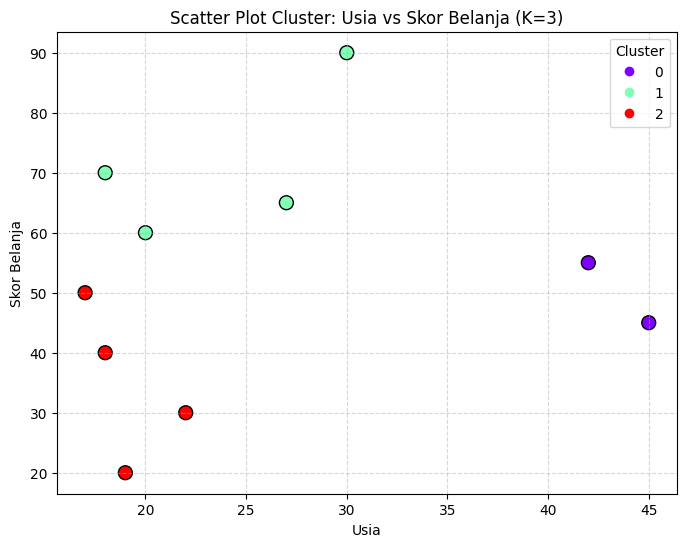

In [100]:
import matplotlib.pyplot as plt

# Scatter Plot berdasarkan df_k3
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df_k3['usia'], df_k3['skor_belanja'], c=df_k3['cluster'], cmap='rainbow', s=100, edgecolors='black')

# Label dan judul
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster: Usia vs Skor Belanja (K=3)')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)

# Menampilkan plot
plt.show()

#### Scatter plot untuk K=5

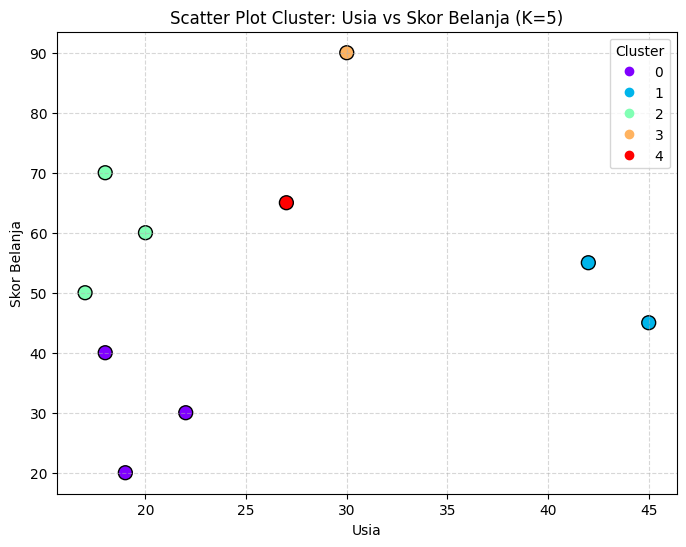

In [101]:
import matplotlib.pyplot as plt

# Scatter Plot berdasarkan df_k5
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df_k5['usia'], df_k5['skor_belanja'], c=df_k5['cluster'], cmap='rainbow', s=100, edgecolors='black')

# Label dan judul
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster: Usia vs Skor Belanja (K=5)')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)

# Menampilkan plot
plt.show()

#### Scatter plot untuk K=3 tanpa Scaling

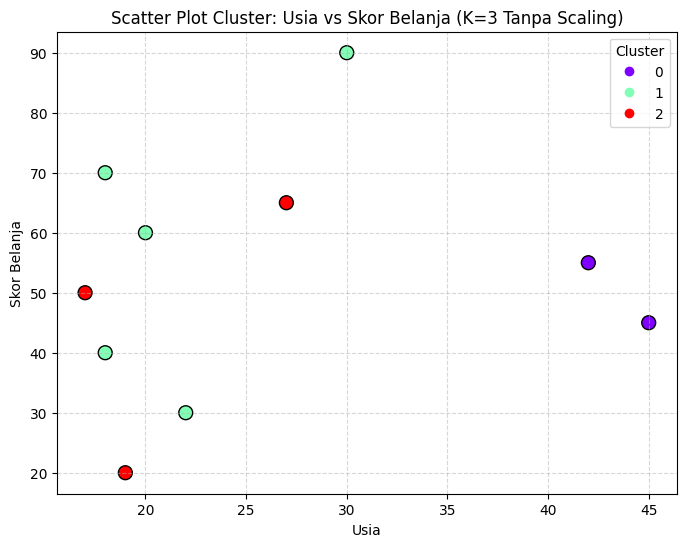

In [102]:
import matplotlib.pyplot as plt

# Scatter Plot berdasarkan df_k3_noScaling
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df_k3_noScaling['usia'], df_k3_noScaling['skor_belanja'], c=df_k3_noScaling['cluster'], cmap='rainbow', s=100, edgecolors='black')

# Label dan judul
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Cluster: Usia vs Skor Belanja (K=3 Tanpa Scaling)')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)

# Menampilkan plot
plt.show()

## Refleksi

### 9. Bagaimana K-Means menemukan kelompok tanpa label?


* Jawab: <br>
K-Means menemukan kelompok dengan mengelompokkan data berdasarkan kemiripan karakteristiknya tanpa memerlukan label. Algoritma ini menentukan centroid sebagai pusat cluster, kemudian memasukkan setiap data ke cluster dengan centroid terdekat. Setelah itu, centroid diperbarui berdasarkan rata-rata data hingga hasil pengelompokan nya stabil.

### 10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?


* Jawab: <br>
Metode Elbow menunjukkan siku di K=3 karena penambahan jumlah cluster hingga tiga kelompok menurunkan nilai inertia secara signifikan. Setelah K=3, penurunan inertia mulai melambat sehingga penambahan cluster baru tidak memberikan peningkatan yang besar. Jadi, K=3 dapat dipilih sebagai jumlah cluster yang sesuai.


### 11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?


* Jawab: <br>
Scaling penting karena K-Means menggunakan jarak untuk mengelompokkan data, sedangkan setiap fitur memiliki rentang nilai yang berbeda. Tanpa scaling, fitur dengan nilai besar, seperti pendapatan, dapat lebih mendominasi perhitungan jarak. Dengan scaling menggunakan StandardScaler, skala setiap fitur menjadi sebanding sehingga hasil clustering lebih seimbang.
